
=== LINEAR ALGEBRA ANALYSIS ===
Rank: 8
Nullity: 1
Rank of augmented matrix: 9
System is inconsistent

=== INDEPENDENT FEATURES ===
studytime, failures, absences, G1, G2, freetime, goout

=== MODEL COEFFICIENTS ===
intercept   :  10.1139
studytime   :  -0.1655
failures    :  -0.2902
absences    :   0.3281
G1          :   0.4785
G2          :   3.6422
freetime    :   0.1504
goout       :   0.0435

=== COEFFICIENTS ===
           standardized  original units
intercept       10.1139         -1.9426
studytime       -0.1655         -0.1959
failures        -0.2902         -0.3745
absences         0.3281          0.0408
G1               0.4785          0.1446
G2               3.6422          0.9792
freetime         0.1504          0.1485
goout            0.0435          0.0386

=== MATRIX CONDITIONING ===
Smallest eigenvalue: 50.7583
Largest eigenvalue: 706.5204
Condition number: 13.92

=== MODEL PERFORMANCE ===
Training RMSE : 1.888
Training R²   : 0.827
Testing RMSE  : 1.906
Testing R²    

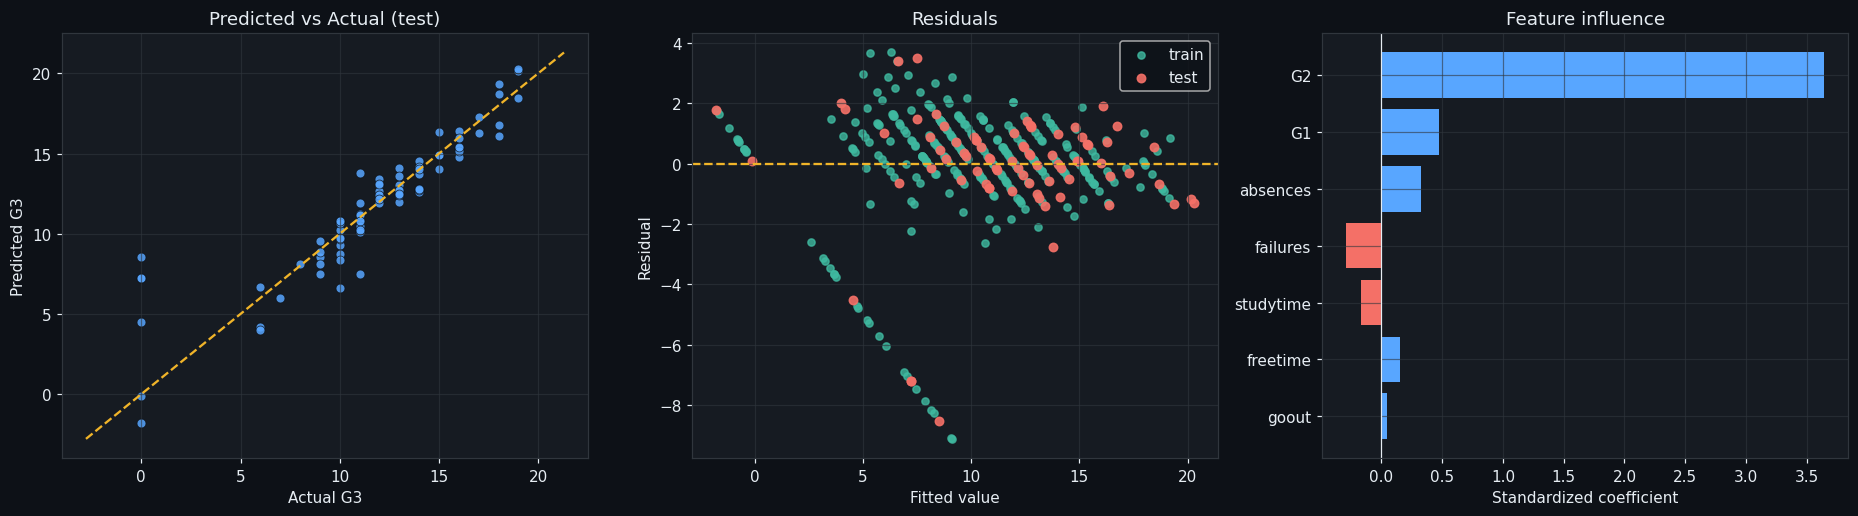

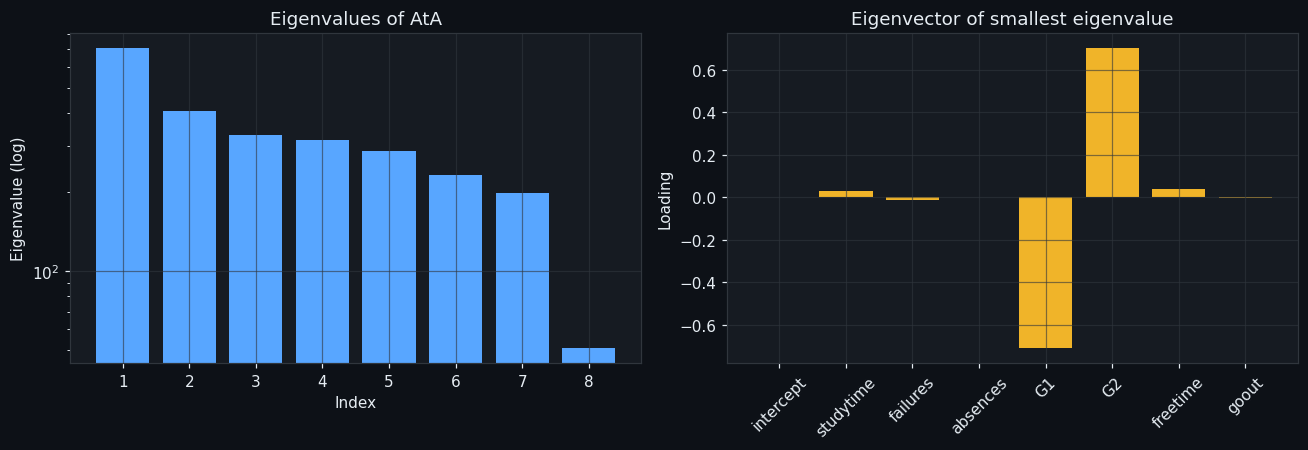

In [3]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from scipy.linalg import solve_triangular
import os
import urllib.request
import zipfile


# =========================================================
# 1. DOWNLOAD AND LOAD DATASET
# =========================================================

if not os.path.exists("student-mat.csv"):
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

    urllib.request.urlretrieve(url, "student_parent.zip")

    with zipfile.ZipFile("student_parent.zip", "r") as z:
        z.extract("student.zip")

    with zipfile.ZipFile("student.zip", "r") as z:
        z.extract("student-mat.csv")

    os.remove("student_parent.zip")
    os.remove("student.zip")


# =========================================================
# 2. GRAPH STYLE
# =========================================================

BG = "#0d1117"
FG = "#e6edf3"
GRID = "#30363d"

BLUE = "#58a6ff"
AMBER = "#f0b429"
TEAL = "#3fb9a0"
ROSE = "#f47067"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": "#161b22",
    "axes.edgecolor": GRID,
    "axes.labelcolor": FG,
    "text.color": FG,
    "xtick.color": FG,
    "ytick.color": FG,
    "grid.color": GRID,
    "axes.grid": True,
    "grid.alpha": 0.6,
    "figure.dpi": 110
})


# =========================================================
# 3. READ DATA
# =========================================================

df = pd.read_csv("student-mat.csv", sep=";")


# =========================================================
# 4. SELECT FEATURES
# =========================================================

FEATURES = [
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "freetime",
    "goout"
]

# Deliberately create a dependent feature
df["G_sum"] = df["G1"] + df["G2"]

CANDIDATES = FEATURES + ["G_sum"]


# =========================================================
# 5. TRAIN / TEST SPLIT
# =========================================================

rng = np.random.default_rng(42)

indices = rng.permutation(len(df))

n_train = int(0.8 * len(df))

train_idx = indices[:n_train]
test_idx = indices[n_train:]

X_train = df.loc[train_idx, CANDIDATES].to_numpy(float)
X_test = df.loc[test_idx, CANDIDATES].to_numpy(float)

y_train = df.loc[train_idx, "G3"].to_numpy(float)
y_test = df.loc[test_idx, "G3"].to_numpy(float)


# =========================================================
# 6. STANDARDIZATION
# =========================================================

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

Z_train = (X_train - mean) / std
Z_test = (X_test - mean) / std


# =========================================================
# 7. RREF, RANK AND NULLITY
# =========================================================

columns = ["intercept"] + CANDIDATES

M = sp.Matrix(
    np.column_stack([
        np.ones(len(train_idx)),
        X_train
    ]).astype(int)
)

_, pivots = M.rref()

rank_A = len(pivots)

m, n = M.shape

rank_augmented = M.row_join(
    sp.Matrix(y_train.astype(int))
).rank()

print("\n=== LINEAR ALGEBRA ANALYSIS ===")

print("Rank:", rank_A)
print("Nullity:", n - rank_A)
print("Rank of augmented matrix:", rank_augmented)

if rank_augmented == rank_A:
    print("System is consistent")
else:
    print("System is inconsistent")


# =========================================================
# 8. KEEP ONLY INDEPENDENT FEATURES
# =========================================================

independent_features = [
    columns[i]
    for i in pivots
    if columns[i] != "intercept"
]

keep = [
    CANDIDATES.index(feature)
    for feature in independent_features
]

names = ["intercept"] + independent_features

A = np.column_stack([
    np.ones(len(train_idx)),
    Z_train[:, keep]
])

A_test = np.column_stack([
    np.ones(len(test_idx)),
    Z_test[:, keep]
])

print("\n=== INDEPENDENT FEATURES ===")
print(", ".join(independent_features))


# =========================================================
# 9. GRAM-SCHMIDT / QR DECOMPOSITION
# =========================================================

def gram_schmidt(A):
    A = A.astype(float)

    m, n = A.shape

    Q = np.zeros((m, n))
    R = np.zeros((n, n))

    V = A.copy()

    for j in range(n):

        R[j, j] = np.linalg.norm(V[:, j])

        Q[:, j] = V[:, j] / R[j, j]

        for k in range(j + 1, n):

            R[j, k] = Q[:, j] @ V[:, k]

            V[:, k] -= R[j, k] * Q[:, j]

    return Q, R


Q, R = gram_schmidt(A)


# =========================================================
# 10. PROJECTION
# =========================================================

projection = Q @ (Q.T @ y_train)

residual = y_train - projection


# =========================================================
# 11. LEAST SQUARES
# =========================================================

coefficients = solve_triangular(
    R,
    Q.T @ y_train
)

print("\n=== MODEL COEFFICIENTS ===")

for name, value in zip(names, coefficients):
    print(f"{name:12s}: {value:8.4f}")


# =========================================================
# 12. COEFFICIENTS IN ORIGINAL UNITS
# =========================================================

original_coefficients = [
    coefficients[0]
    - np.sum(
        coefficients[1:] *
        mean[keep] /
        std[keep]
    )
]

original_coefficients += list(
    coefficients[1:] / std[keep]
)

coef = pd.DataFrame(
    {
        "standardized": coefficients,
        "original units": original_coefficients
    },
    index=names
)

print("\n=== COEFFICIENTS ===")
print(coef.round(4))


# =========================================================
# 13. EIGENVALUES AND CONDITIONING
# =========================================================

def spectrum(matrix):
    eigenvalues, eigenvectors = np.linalg.eigh(
        matrix.T @ matrix
    )

    return eigenvalues[::-1], eigenvectors[:, ::-1]


# With G_sum
A_full = np.column_stack([
    np.ones(len(train_idx)),
    Z_train
])

eigenvalues_full, _ = spectrum(A_full)

# Without G_sum
eigenvalues, eigenvectors = spectrum(A)

condition_number = (
    eigenvalues[0] /
    eigenvalues[-1]
)

print("\n=== MATRIX CONDITIONING ===")

print(
    "Smallest eigenvalue:",
    round(eigenvalues[-1], 4)
)

print(
    "Largest eigenvalue:",
    round(eigenvalues[0], 4)
)

print(
    "Condition number:",
    round(condition_number, 2)
)


# =========================================================
# 14. PREDICTIONS
# =========================================================

train_predictions = A @ coefficients

test_predictions = A_test @ coefficients

train_residuals = y_train - train_predictions
test_residuals = y_test - test_predictions


# =========================================================
# 15. EVALUATION
# =========================================================

def metrics(actual, predicted):

    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )

    r2 = 1 - (
        np.sum((actual - predicted) ** 2)
        /
        np.sum((actual - actual.mean()) ** 2)
    )

    return rmse, r2


train_rmse, train_r2 = metrics(
    y_train,
    train_predictions
)

test_rmse, test_r2 = metrics(
    y_test,
    test_predictions
)


print("\n=== MODEL PERFORMANCE ===")

print(f"Training RMSE : {train_rmse:.3f}")
print(f"Training R²   : {train_r2:.3f}")

print(f"Testing RMSE  : {test_rmse:.3f}")
print(f"Testing R²    : {test_r2:.3f}")


# =========================================================
# 16. GRAPHS
# =========================================================

fig, ax = plt.subplots(
    1,
    3,
    figsize=(17, 4.8)
)


# ---------------------------------------------------------
# Graph 1: Predicted vs Actual
# ---------------------------------------------------------

ax[0].scatter(
    y_test,
    test_predictions,
    c=BLUE,
    s=34,
    alpha=0.85,
    edgecolor=BG,
    lw=0.5
)

lim = [
    min(y_test.min(), test_predictions.min()) - 1,
    max(y_test.max(), test_predictions.max()) + 1
]

ax[0].plot(
    lim,
    lim,
    color=AMBER,
    ls="--"
)

ax[0].set(
    xlabel="Actual G3",
    ylabel="Predicted G3",
    title="Predicted vs Actual (test)"
)


# ---------------------------------------------------------
# Graph 2: Residuals
# ---------------------------------------------------------

ax[1].scatter(
    train_predictions,
    train_residuals,
    c=TEAL,
    s=22,
    alpha=0.8,
    label="train"
)

ax[1].scatter(
    test_predictions,
    test_residuals,
    c=ROSE,
    s=30,
    alpha=0.9,
    label="test"
)

ax[1].axhline(
    0,
    color=AMBER,
    ls="--"
)

ax[1].set(
    xlabel="Fitted value",
    ylabel="Residual",
    title="Residuals"
)

ax[1].legend(
    facecolor=BG
)


# ---------------------------------------------------------
# Graph 3: Feature Influence
# ---------------------------------------------------------

order = np.argsort(
    np.abs(coefficients[1:])
)

ax[2].barh(
    np.array(independent_features)[order],
    coefficients[1:][order],
    color=[
        BLUE if c > 0 else ROSE
        for c in coefficients[1:][order]
    ]
)

ax[2].axvline(
    0,
    color=FG,
    lw=0.8
)

ax[2].set(
    xlabel="Standardized coefficient",
    title="Feature influence"
)


plt.tight_layout()
plt.show()


# =========================================================
# 17. EIGENVALUE GRAPHS
# =========================================================

fig, ax = plt.subplots(
    1,
    2,
    figsize=(12, 4.2)
)


# Eigenvalues

ax[0].bar(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    color=BLUE
)

ax[0].set_yscale("log")

ax[0].set(
    xlabel="Index",
    ylabel="Eigenvalue (log)",
    title="Eigenvalues of AtA"
)


# Smallest eigenvalue eigenvector

ax[1].bar(
    names,
    eigenvectors[:, -1],
    color=AMBER
)

ax[1].tick_params(
    axis="x",
    rotation=45
)

ax[1].set(
    ylabel="Loading",
    title="Eigenvector of smallest eigenvalue"
)


plt.tight_layout()
plt.show()